In [1]:
%pip install ultralytics

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

base_dir = '/content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'valid')
test_dir = os.path.join(base_dir, 'test')

# base_dir = '/content/drive/My Drive/'

assert os.path.exists(base_dir), f"Base directory not found"
assert os.path.exists(train_dir), f"Train directory not found: {train_dir}"
assert os.path.exists(val_dir), f"Validation directory not found: {val_dir}"
assert os.path.exists(test_dir), f"Test directory not found: {test_dir}"

# traffic-road-object-detection-polish-12k/road_detection/road_detection

In [3]:
import os

for root, dirs, files in os.walk(base_dir):
    print(f"Root: {root}")
    print(f"Directories: {dirs}")
    print(f"Files: {len(files)} files found\n")


Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection
Directories: ['test', 'valid', 'train']
Files: 0 files found

Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/test
Directories: ['images', 'labels']
Files: 1 files found

Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/test/images
Directories: []
Files: 484 files found

Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/test/labels
Directories: []
Files: 484 files found

Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/valid
Directories: ['labels', 'images']
Files: 1 files found

Root: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/valid/labels
Directories: []
Files: 935 files found

Root: /content/drive/My Drive/traffic-road-object-de

First Image Shape: (480, 640, 3)
First Image Boxes: [[538, 245, 564, 288], [445, 340, 591, 475], [314, 338, 360, 392], [379, 340, 415, 379], [366, 339, 387, 365], [338, 299, 346, 311], [353, 300, 359, 311], [323, 298, 329, 311]]
First Image Class IDs: [1, 0, 0, 0, 0, 2, 2, 7]


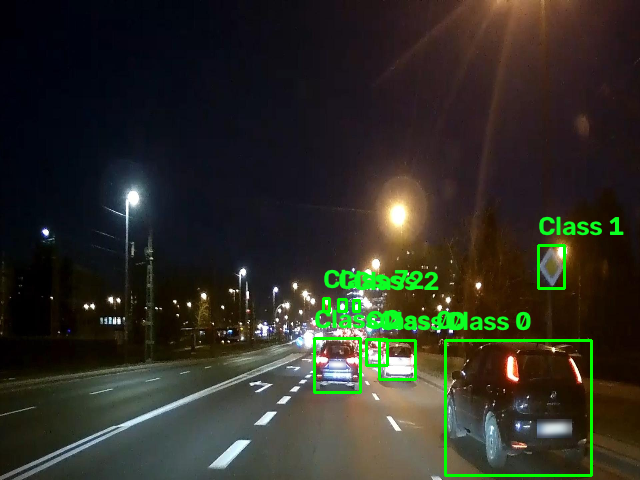

In [4]:
import os
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

# Paths to the dataset directories
train_images_path = os.path.join(test_dir, "images")
train_labels_path = os.path.join(test_dir, "labels")

img_width, img_height = 640, 480  # Assumed image size (adjust based on your actual image size)

# Helper function to parse a single YOLO label line
def parse_yolo_label(label_line):
    label_parts = label_line.strip().split()
    class_id = int(label_parts[0])
    center_x = float(label_parts[1])
    center_y = float(label_parts[2])
    width = float(label_parts[3])
    height = float(label_parts[4])
    return class_id, center_x, center_y, width, height

# Convert YOLO format to bounding box coordinates in image pixel values
def yolo_to_image_coords(center_x, center_y, width, height, img_width, img_height):
    box_x1 = int((center_x - width / 2) * img_width)
    box_y1 = int((center_y - height / 2) * img_height)
    box_x2 = int((center_x + width / 2) * img_width)
    box_y2 = int((center_y + height / 2) * img_height)
    return box_x1, box_y1, box_x2, box_y2

# Load images and corresponding labels
def load_data(images_path, labels_path):
    images = []
    boxes = []
    class_ids = []

    for image_file in os.listdir(images_path):
        if image_file.endswith('.jpg') or image_file.endswith('.png'):
            # Load image
            image_path = os.path.join(images_path, image_file)
            image = cv2.imread(image_path)
            image = cv2.resize(image, (img_width, img_height))  # Adjust size

            # Append image to list
            images.append(image)

            # Load corresponding label
            label_file = os.path.splitext(image_file)[0] + '.txt'
            label_path = os.path.join(labels_path, label_file)

            with open(label_path, 'r') as file:
                label_data = file.readlines()
                image_boxes = []
                image_class_ids = []

                for label_line in label_data:
                    class_id, center_x, center_y, width, height = parse_yolo_label(label_line)
                    box_x1, box_y1, box_x2, box_y2 = yolo_to_image_coords(center_x, center_y, width, height, img_width, img_height)

                    # Append box and class_id to respective lists
                    image_boxes.append([box_x1, box_y1, box_x2, box_y2])
                    image_class_ids.append(class_id)

                boxes.append(image_boxes)
                class_ids.append(image_class_ids)

    return np.array(images), boxes, class_ids

# Load training data
train_images, train_boxes, train_class_ids = load_data(train_images_path, train_labels_path)

# Example: Inspect the first image, boxes, and classes
print("First Image Shape:", train_images[0].shape)
print("First Image Boxes:", train_boxes[0])
print("First Image Class IDs:", train_class_ids[0])

# Visualize an image with bounding boxes drawn
def visualize_image_with_boxes(image, boxes, class_ids):
    image_copy = image.copy()  # Create a copy to avoid modifying the original image
    for (box, class_id) in zip(boxes, class_ids):
        x1, y1, x2, y2 = box
        # Draw rectangle and class id
        cv2.rectangle(image_copy, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(image_copy, f'Class {class_id}', (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (36,255,12), 2)
    # cv2.imshow("Image with Bounding Boxes", image)
    cv2_imshow(image_copy)

# Example visualization
visualize_image_with_boxes(train_images[0], train_boxes[0], train_class_ids[0])


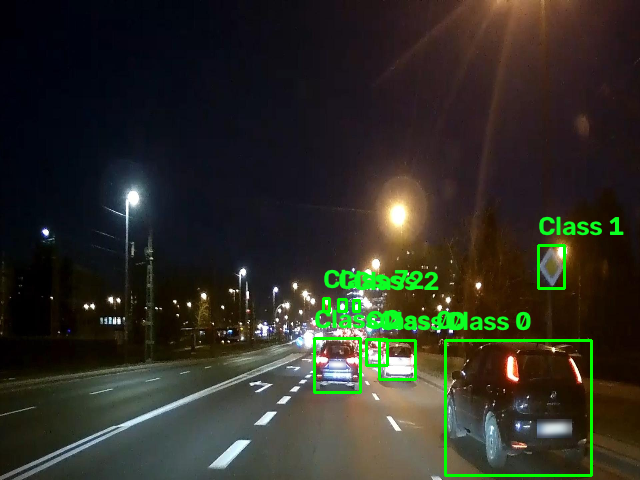

In [5]:
from google.colab.patches import cv2_imshow;

def visualize_image_with_boxes(image, boxes, class_ids):
    image_copy = image.copy()  # Create a copy to avoid modifying the original image
    for (box, class_id) in zip(boxes, class_ids):
        x1, y1, x2, y2 = box
        # Draw rectangle and class id
        cv2.rectangle(image_copy, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(image_copy, f'Class {class_id}', (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (36,255,12), 2)
    # cv2.imshow("Image with Bounding Boxes", image)
    cv2_imshow(image_copy)

# Example visualization
visualize_image_with_boxes(train_images[0], train_boxes[0], train_class_ids[0])


In [6]:
from ultralytics import YOLO
import os

# Define paths
dataset_root = base_dir
train_images_dir = os.path.join(train_dir, 'images')
train_labels_dir = os.path.join(train_dir, 'labels')
valid_images_dir = os.path.join(val_dir, 'images')
valid_labels_dir = os.path.join(val_dir, 'labels')

# Define the dataset configuration file
data_config = f"""
path: {dataset_root}

train: {dataset_root}/valid
val: {dataset_root}/test

nc: 8  # Number of classes, adjust based on your dataset
names: ['car', 'pedestrian', 'bike', 'bus', 'truck', 'motorcycle', 'traffic_sign', 'unknown']  # Add your class names
"""

# Write this configuration to a YAML file
data_yaml_path = 'data.yaml'
with open(data_yaml_path, 'w') as file:
    file.write(data_config)

# Initialize the YOLOv5 model (pre-trained on COCO)
model = YOLO('yolov5s.pt')  # Use the small version of YOLOv5 for faster training

# Train the model
model.train(epochs=10, imgsz=640, batch=16, data=data_yaml_path)  # Adjust epochs, image size, batch size, and device


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PRO TIP 💡 Replace 'model=yolov5s.pt' with new 'model=yolov5su.pt'.
YOLOv5 'u' models are trained with https://github.com/ultralytics/ultralytics and feature improved performance vs standard YOLOv5 models trained with https://github.com/ultralytics/yolov5.
Ultralytics 8.4.116 🚀 Python-3.12.13 torch-2.9.0+cpu CPU (AMD EPYC 7B13)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, det

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x798167889e80>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

In [7]:
# Evaluate the model on validation data
results = model.val()
print(results)


Ultralytics 8.4.116 🚀 Python-3.12.13 torch-2.9.0+cpu CPU (AMD EPYC 7B13)
YOLOv5s summary (fused): 85 layers, 9,114,632 parameters, 0 gradients, 23.8 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 375.1±235.7 MB/s, size: 336.3 KB)
val: Scanning /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/test/labels.cache... 484 images, 0 backgrounds, 228 corrupt: 100% ━━━━━━━━━━━━ 484/484 203.0Mit/s 0.0s
val: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/test/images/Film10-Wykonano-za-pomoca-Clipchamp_mp4-0002_jpg.rf.4be06e1a055c40b022e997c625d237bb.jpg: ignoring corrupt image/label: Label class 9 exceeds dataset class count 8. Possible class labels are 0-7
val: /content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/test/images/Film10-Wykonano-za-pomoca-Clipchamp_mp4-0002_jpg.rf.4be06e1a055c40b022e997c625d237bb_aug_out_0.png: ignoring corrupt image/label:


0: 480x640 5 cars, 6 pedestrians, 1 truck, 3 unknowns, 51.9ms
Speed: 1.7ms preprocess, 51.9ms inference, 0.6ms postprocess per image at shape (1, 3, 480, 640)


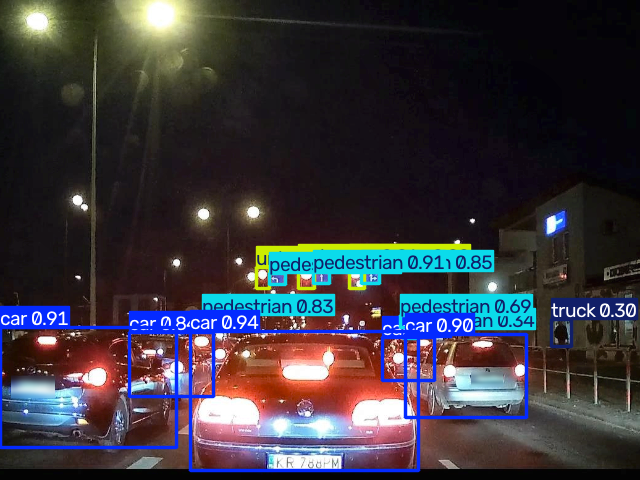

In [22]:
import random

image_index = random.randint(0, len(train_images) - 1)
results = model.predict(train_images[image_index])
cv2_imshow(results[0].plot())

In [23]:
from google.colab import files
import shutil

# For Ultralytics YOLO (YOLOv8, YOLOv11, YOLO26 etc.)
shutil.copy('/content/runs/detect/train/weights/best.pt', base_dir + '/best.pt')

# For older versions like YOLOv5, use this path:
# files.download('/content/yolov5/runs/train/exp/weights/best.pt')

'/content/drive/My Drive/traffic-road-object-detection-polish-12k/road_detection/road_detection/best.pt'